# Pretrained CNN: ResNet-18

**Final project · Intelligent museum guide** · issue #8

Deliverable 3: a **pretrained convolutional network** for the same five styles, on the same split as the
baseline and the MLP. The ResNet-18 of `torchvision` was trained on ImageNet (1.2 million photos): its filters
already detect edges, textures and shapes, which is exactly what the MLP could not learn from 1 050 paintings.
We replace its last layer by a new head with 5 outputs and compare, as in TP07:

1. **Head only**: the backbone is frozen, only the new `Linear(512, 5)` is trained.
2. **Last block + head**: `layer4` is fine-tuned with a smaller learning rate.
3. **Whole network**: every layer is fine-tuned, again with a small learning rate for the pretrained weights.
4. **Logistic regression on the frozen ResNet features**: a classical model on deep features, which is cheap
   to train and to update with new paintings.

As for the MLP, each variant is trained with **three seeds** and compared on the validation set; the test set is
used once, at the end. For reference, on the test set: logistic regression on colour histograms 0.396, MLP 0.431.

In [1]:
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

sys.path.append("..")
from src.data import FlipDataset, load_splits
from src.models import ResNetClassifier, count_parameters
from src.plots import plot_history
from src.train import RESULTS_DIR, classification_metrics, evaluate, fit, predict, save_json

np.random.seed(0)
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
SIZE = 128                     # input size in pixels
LR_HEAD, LR_BACKBONE = 1e-3, 1e-4   # the new head learns fast, the pretrained weights are only adjusted
loss_fn = nn.CrossEntropyLoss()
print("device:", device)

device: mps


## Data

The images are normalised with the **ImageNet** mean and standard deviation: a pretrained model must receive its
inputs prepared as during its pre-training. The images stay at 128 × 128 pixels: the ResNet was pretrained on 224 × 224 photos, but a convolutional network accepts any size, and 128 pixels keeps the CPU cost per painting about three times lower than 224 on the kiosks. The training loader flips half of the paintings at
random at each epoch (`FlipDataset`), as for the final MLP.

In [2]:
splits, classes = load_splits("imagenet", size=SIZE)
X_train, y_train = splits["train"]
train_loader = DataLoader(FlipDataset(X_train, y_train), batch_size=64, shuffle=True)
train_eval_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128)
val_loader = DataLoader(TensorDataset(*splits["val"]), batch_size=128)
test_loader = DataLoader(TensorDataset(*splits["test"]), batch_size=128)

train 1050 images | per class {'Baroque': 210, 'Cubism': 210, 'Impressionism': 210, 'Pop_Art': 210, 'Ukiyo_e': 210}
val    225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}
test   225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}


## The model

`ResNetClassifier` (`src/models.py`) loads the ImageNet weights and replaces the 1 000-class head by a new
`Linear(512, 5)` with random weights. It always stays in `eval()` mode, even when `fit` calls `model.train()`:
as in TP07, with 1 050 images we keep the batch-norm statistics learned on ImageNet (the weights are still
trained normally; ResNet-18 has no dropout, so nothing else changes).

In [3]:
torch.manual_seed(0)
model = ResNetClassifier()
print("new head:", model.resnet.fc)
print(f"parameters: {count_parameters(model):,d} (head: {count_parameters(model.resnet.fc):,d})")
loss0, acc0 = evaluate(model.to(device), val_loader, loss_fn, device)
print(f"untrained head: val loss {loss0:.3f} (ln 5 = {np.log(5):.3f}), val accuracy {acc0:.3f}")

new head: Linear(in_features=512, out_features=5, bias=True)
parameters: 11,179,077 (head: 2,565)


untrained head: val loss 1.809 (ln 5 = 1.609), val accuracy 0.204


## 1-3. Head only, last block, whole network

`make_optimizer` first freezes every parameter (`requires_grad = False`: autograd no longer computes their
gradient), then unfreezes the head and, depending on the variant, `layer4` or the whole backbone. The optimiser
gets two **parameter groups**: `LR_HEAD` for the new head, `LR_BACKBONE` for the pretrained weights, which we only
want to adjust. Each run uses at most 30 epochs and early stopping (patience 5).

In [4]:
def make_optimizer(model, trainable):
    """Freeze everything, then train the head and, if asked, layer4 or the whole backbone."""
    for p in model.parameters():
        p.requires_grad = False
    groups = [{"params": list(model.resnet.fc.parameters()), "lr": LR_HEAD}]
    if trainable == "layer4":
        groups.append({"params": list(model.resnet.layer4.parameters()), "lr": LR_BACKBONE})
    elif trainable == "all":
        backbone = [p for name, p in model.named_parameters() if not name.startswith("resnet.fc")]
        groups.append({"params": backbone, "lr": LR_BACKBONE})
    for group in groups:
        for p in group["params"]:
            p.requires_grad = True
    return torch.optim.Adam(groups)


def run(trainable, seeds=(0, 1, 2)):
    """Train one variant with several seeds and average the results at the best epoch."""
    val_accs, gaps, best_epochs, times = [], [], [], []
    for seed in seeds:
        torch.manual_seed(seed)
        model = ResNetClassifier()
        history = fit(model, train_loader, val_loader, loss_fn, make_optimizer(model, trainable),
                      n_epochs=30, patience=5, device=device, seed=seed, verbose=False)
        _, train_acc = evaluate(model, train_eval_loader, loss_fn, device)
        _, val_acc = evaluate(model, val_loader, loss_fn, device)
        val_accs.append(val_acc)
        gaps.append(train_acc - val_acc)
        best_epochs.append(history["best_epoch"])
        times.append(history["train_time_s"])
    return {"val_acc": float(np.mean(val_accs)), "val_acc_std": float(np.std(val_accs)),
            "gap": float(np.mean(gaps)), "best_epoch": float(np.mean(best_epochs)),
            "train_time_s": float(np.mean(times)), "n_trainable": count_parameters(model, trainable_only=True)}


variants = {"head only": "head", "layer4 + head": "layer4", "whole network": "all"}
results = {}
for name, trainable in variants.items():
    results[name] = r = run(trainable)
    print(f"{name:14s} val acc {r['val_acc']:.3f} ± {r['val_acc_std']:.3f} | train-val gap {r['gap']:.3f} | "
          f"best epoch {r['best_epoch']:4.1f} | {r['train_time_s']:5.1f} s per run | "
          f"{r['n_trainable']:>10,d} trainable params")

head only      val acc 0.711 ± 0.004 | train-val gap 0.142 | best epoch 10.7 |   7.8 s per run |      2,565 trainable params


layer4 + head  val acc 0.757 ± 0.024 | train-val gap 0.192 | best epoch  2.7 |   5.0 s per run |  8,396,293 trainable params


whole network  val acc 0.770 ± 0.015 | train-val gap 0.156 | best epoch  4.0 |  11.8 s per run | 11,179,077 trainable params


**What we see.** Pretrained features change everything. With only the new head trained (2 565 weights), the
ResNet reaches 0.711 on validation, against 0.40 for the best MLP with 2 million trained weights. Fine-tuning
adds 5 to 6 points: 0.757 ± 0.024 for `layer4` and 0.770 ± 0.015 for the whole network, a difference within the
seed noise. Fine-tuning learns fast and overfits fast: the best epoch is 3 to 4, against about 11 for the head
alone. The ImageNet filters already respond to edges, textures and shapes, which is what brushwork and geometry
are made of, and what the MLP could not learn from 1 050 paintings.

## 4. Logistic regression on the frozen ResNet features

The pretrained backbone, without its head, turns each painting into 512 numbers (`ResNetClassifier.features`,
the output of the last average pooling). A logistic regression on these features is a classical model again, but
on representations learned by a deep network. It trains in seconds, so adding a new painting or a new style
would not require any GPU. `C` is chosen on the validation set.

In [5]:
torch.manual_seed(0)
backbone = ResNetClassifier().to(device).eval()      # ImageNet weights; the head is not used


def extract(X):
    """512 ResNet features per image, computed by batches without gradients."""
    with torch.no_grad():
        return torch.cat([backbone.features(xb.to(device)).cpu()
                          for (xb,) in DataLoader(TensorDataset(X), batch_size=128)]).numpy()


start = time.perf_counter()
F_train = extract(X_train)
extract_time = time.perf_counter() - start
F_val, F_test = extract(splits["val"][0]), extract(splits["test"][0])
y_tr, y_va, y_te = y_train.numpy(), splits["val"][1].numpy(), splits["test"][1].numpy()
print("features:", F_train.shape, f"| extraction of the training set: {extract_time:.1f} s on {device}")

val_acc_lr = {}
for C in [1e-4, 1e-3, 1e-2, 1e-1, 1]:
    lr_model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)).fit(F_train, y_tr)
    val_acc_lr[C] = lr_model.score(F_val, y_va)
    print(f"C {C:6g}  train acc {lr_model.score(F_train, y_tr):.3f}  val acc {val_acc_lr[C]:.3f}")
best_C = max(val_acc_lr, key=val_acc_lr.get)
print("best C:", best_C)

features: (1050, 512) | extraction of the training set: 0.4 s on mps
C 0.0001  train acc 0.750  val acc 0.689
C  0.001  train acc 0.818  val acc 0.733
C   0.01  train acc 0.935  val acc 0.720
C    0.1  train acc 1.000  val acc 0.707
C      1  train acc 1.000  val acc 0.671
best C: 0.001


**What we see.** With a strong penalty (`C = 0.001`), the logistic regression on the 512 frozen features
reaches 0.733 on validation, close to the trained head (0.711), which is the same linear model trained with Adam
and early stopping. A weaker penalty learns the training set by heart (train accuracy 1.0) and loses up to 6
points on validation. Extracting the features of the 1 050 training paintings takes less than a second on the
laptop GPU (MPS).

## Final models and test set

We keep the best fine-tuning variant on the validation set, train it once more (seed 0), plot its learning
curves and evaluate it **once** on the test set. The logistic regression on features is a different deployment
option for the director, so we evaluate it on the test set too. The fine-tuned weights are saved in
`results/resnet.pt` (git-ignored) for the CPU benchmark.

best fine-tuning variant on validation: whole network


stopped after 8 epochs, best epoch 3, 11 s on mps


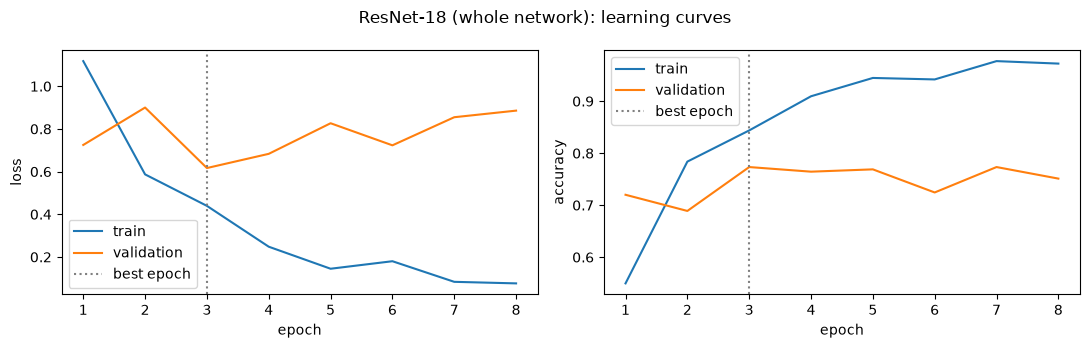

In [6]:
best_variant = max(results, key=lambda k: results[k]["val_acc"])
print("best fine-tuning variant on validation:", best_variant)

torch.manual_seed(0)
model = ResNetClassifier()
history = fit(model, train_loader, val_loader, loss_fn, make_optimizer(model, variants[best_variant]),
              n_epochs=30, patience=5, device=device, verbose=False)
print(f"stopped after {len(history['val_loss'])} epochs, best epoch {history['best_epoch']}, "
      f"{history['train_time_s']:.0f} s on {device}")
plot_history(history, f"ResNet-18 ({best_variant}): learning curves", RESULTS_DIR / "resnet_curves.png")

ResNet-18, whole network                 test accuracy 0.796, macro-F1 0.792
logistic regression on ResNet features   test accuracy 0.769, macro-F1 0.769


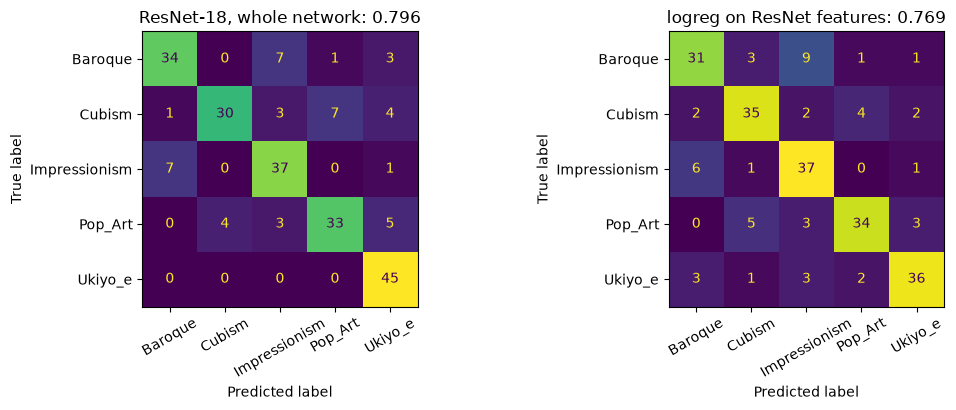

In [7]:
test_ft = classification_metrics(*predict(model, test_loader, device))

start = time.perf_counter()
lr_model = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=3000)).fit(F_train, y_tr)
lr_time = time.perf_counter() - start
test_lr = classification_metrics(y_te, lr_model.predict(F_test))

for name, t in [(f"ResNet-18, {best_variant}", test_ft), ("logistic regression on ResNet features", test_lr)]:
    print(f"{name:40s} test accuracy {t['accuracy']:.3f}, macro-F1 {t['macro_f1']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, t) in zip(axes, [(f"ResNet-18, {best_variant}", test_ft), ("logreg on ResNet features", test_lr)]):
    ConfusionMatrixDisplay(np.array(t["confusion_matrix"]), display_labels=classes).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}: {t['accuracy']:.3f}")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "resnet_confusion.png", dpi=120)
plt.show()

torch.save(model.state_dict(), RESULTS_DIR / "resnet.pt")
save_json({
    "finetuned": {**test_ft, "variant": best_variant, "size": SIZE, "lr_head": LR_HEAD, "lr_backbone": LR_BACKBONE,
                  "n_params": count_parameters(model), "train_time_s": history["train_time_s"],
                  "best_epoch": history["best_epoch"], "device": device, "history": history},
    "logreg_features": {**test_lr, "C": best_C, "val_accuracy": val_acc_lr[best_C],
                        "n_params": int(lr_model[-1].coef_.size + lr_model[-1].intercept_.size),
                        "train_time_s": extract_time + lr_time},
    "variants": results,
}, RESULTS_DIR / "resnet.json")

## What we take from it

- **The fine-tuned ResNet-18 reaches 0.796 on the test set** (macro-F1 0.792), almost twice the MLP (0.431) and
  the best classical model on pixels or colour histograms (0.396). A gap of 35 to 40 points is far beyond the
  standard error of about 3 points: on accuracy, the pretrained CNN is clearly worth it.
- **The logistic regression on ResNet features reaches 0.769** (macro-F1 0.769), 2.7 points below, which is
  within the noise. It has 2 565 trained weights and trains in under a second once the features are extracted.
- **The errors make sense.** Ukiyo-e is always recognised (45 / 45), then Impressionism (37), Baroque (34),
  Pop Art (33) and Cubism (30, against 10 for the MLP). Baroque and Impressionism, both figurative oil paintings,
  are confused with each other (7 errors each way), and some Cubist works with flat areas of colour are taken for
  Pop Art (7). The logistic regression makes the same kind of errors, with more Cubism (35) and less Baroque (31).
- **The curves call for early stopping.** The whole network learns the training set within a few epochs (train
  accuracy 0.97 at epoch 7), while the validation loss is lowest at epoch 3.
- **Both options run the same 11-million-parameter backbone** for every painting, so their CPU cost on a kiosk
  is the same; it is measured in the benchmark (issue #9). We kept 128 × 128 images: 224 pixels, the ImageNet
  resolution, is a lever we did not explore, at about three times the computation per painting.

For the director: the deep features make the difference, more than training the whole network. A frozen ResNet
followed by a logistic regression is an attractive production option, cheap to retrain when the collection
changes and within a few points of the fine-tuned network. Whether a kiosk CPU can afford the backbone is the
remaining question.